# COATI embeddings

- This notebook generates embeddings across several datasets using the **COATI** molecular embedding model
- The three datasets are the MCES dataset by Kretschmer et al (2025), a 30K subset of the ZINC database, and the Biogen ADMET dataset.
- You will need to edit the file paths in the relevant section below.

# Imports

In [10]:
import torch
from coati.models.io.coati import load_e3gnn_smiles_clip_e2e
from coati.generative.coati_purifications import embed_smiles_batch
from rdkit import Chem
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from rdkit.Chem.MolStandardize import rdMolStandardize

## File paths

Edit the following paths

In [ ]:
BIOGEN_PATH  = ''
MCES_PATH    = ''
ZINC30K_PATH = ''

# Model set-up

In [2]:
encoder, tokenizer = load_e3gnn_smiles_clip_e2e(
    freeze=True,
    device="cpu",
    doc_url="s3://terray-public/models/barlow_closed.pkl",
)

Loading model from s3://terray-public/models/barlow_closed.pkl
Loading tokenizer may_closedparen from s3://terray-public/models/barlow_closed.pkl
number of parameters: 12.64M
number of parameters Total: 2.44M xformer: 17.92M Total: 20.36M 
vocab_name not found in tokenizer_vocabs, trying to load from file
Freezing encoder
20561664 params frozen!


In [3]:
def embed(smiles):
    smiles_batch = [Chem.CanonSmiles(s) for s in smiles]
    encoder.eval()
    batch_size = 512
    vec_chunks = []
    for i in tqdm(range(0, len(smiles_batch), batch_size)):
        batch = smiles_batch[i:i + batch_size]
        with torch.inference_mode():
            vecs = embed_smiles_batch(batch, encoder, tokenizer)
        vec_chunks.append(vecs.detach().cpu())
    vecs = torch.cat(vec_chunks, dim=0).numpy()
    return vecs

## MCES

In [6]:
distances = np.load(MCES_PATH)
mces      = distances['mces']
smiles    = distances['smiles']

print(mces.shape)
print(smiles.shape)

(2012094766,)
(63437,)


In [ ]:
# Check SMILES that fail to tokenize.
tokens, bad_idxs = tokenizer.batch_smiles(
    smiles,
    skip_failed=True
)

failed_mask = np.zeros(len(smiles), dtype=np.uint8)
failed_mask[bad_idxs] = 1

np.save('MCES/COATI invalid.npy', failed_mask)

In [ ]:
# Set all invalid SMILES to a dummy molecule so embedding doesn't fail. These will later be censored.
for i in range(len(smiles)):
    if i in bad_idxs:
        smiles[i] = "C"

In [ ]:
embeddings = embed(smiles)
np.save('MCES/COATI MCES embeddings.npy', embeddings)

In [ ]:
embeddings.shape

In [ ]:
X = np.asarray(embeddings, dtype=np.float32)
n = X.shape[0]

# Normalize rows
norms = np.linalg.norm(X, axis=1, keepdims=True)
X = X / np.clip(norms, 1e-12, None)

m = n * (n - 1) // 2

pairwise_cosine = np.memmap(
    "MCES/COATI MCES pairwise cosines.dat",
    dtype="float32",
    mode="w+",
    shape=(m,),
)

offset = 0
chunk_size = 1000

for i_start in tqdm(range(0, n, chunk_size)):
    i_end = min(i_start + chunk_size, n)

    for i in range(i_start, i_end):
        sims = X[i] @ X[i + 1:].T
        pairwise_cosine[offset:offset + len(sims)] = sims
        offset += len(sims)

pairwise_cosine.flush()

print("Expected length:", m)
print("Written length:", offset)

In [ ]:
n = 63437
m = n * (n - 1) // 2

pair_indices = np.memmap(
    "MCES/COATI MCES pairwise indices.dat",
    dtype=np.uint32,
    mode="w+",
    shape=(m, 2),
)

offset = 0

for i in tqdm(range(n - 1)):
    n_pairs = n - i - 1

    pair_indices[offset:offset + n_pairs, 0] = i
    pair_indices[offset:offset + n_pairs, 1] = np.arange(
        i + 1,
        n,
        dtype=np.uint32,
    )

    offset += n_pairs

pair_indices.flush()

print("Expected:", m)
print("Written:", offset)

## MCES figure example

In [16]:
def indices(smiles, smi_a, smi_b):
    """ Return the indices of two molecules in a list of SMILES """
    a_idx = -1
    b_idx = -1
    for i, s in enumerate(smiles):
        if s == smi_a:
            a_idx = i
        if s == smi_b:
            b_idx = i
    return a_idx, b_idx

def condensed_index(i, j, n):
    """ Index into the flattened strict upper triangle (row-major) of an n x n matrix."""
    if i > j:
        i, j = j, i  # cosine similarity is symmetric
    return n * i - i * (i + 1) // 2 + (j - i - 1)

def scale(pairwise_cosine, censored, index):
    """
        COATI produces extreme cosine similarities for all
        molecules. We therefore scale to cosines for the 
        purpose of the MCES example. Bounds are computed on
        uncensored pairs only. 
    """
    lo, hi = np.percentile(pairwise_cosine[~censored], [1, 99])
    return np.clip((pairwise_cosine[index] - lo) / (hi - lo), 0, 1)


In [18]:
# Load the molecules that are censored so we only scale by the appropriate molecules 
censored = np.load('censor_mask.npy') 
censored = censored | (distances['mces'] == -1) 

Cosine similarity: 0.9967469010608809


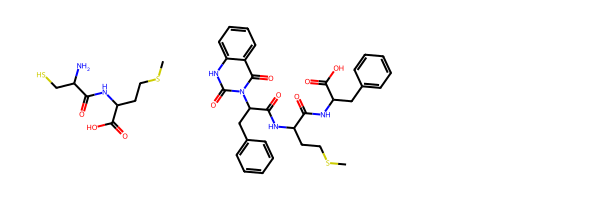

In [19]:
# Locate the correct pairwise cosine for the two pairs
close_pair_a = "CSCCC(C(=O)O)NC(=O)C(CS)N"
close_pair_b = "CSCCC(C(=O)NC(CC1=CC=CC=C1)C(=O)O)NC(=O)C(CC2=CC=CC=C2)N3C(=O)C4=CC=CC=C4NC3=O"

close_pair_mol_a = Chem.MolFromSmiles(close_pair_a)
close_pair_mol_b = Chem.MolFromSmiles(close_pair_b)

a_idx, b_idx  = indices(smiles, close_pair_a, close_pair_b)
index         = condensed_index(a_idx, b_idx, len(smiles))

print(f"Cosine similarity: {scale(pairwise_cosine, censored, index)}")

Chem.Draw.MolsToGridImage([close_pair_mol_a, close_pair_mol_b])

Cosine similarity: 0.5934493660734336


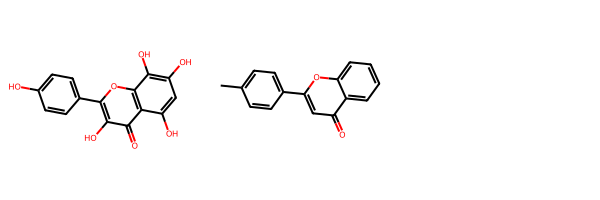

In [20]:
# Locate the correct pairwise cosine for the two pairs
distant_pair_a = "C1=CC(=CC=C1C2=C(C(=O)C3=C(O2)C(=C(C=C3O)O)O)O)O"
distant_pair_b = "CC1=CC=C(C=C1)C2=CC(=O)C3=CC=CC=C3O2"

distant_pair_mol_a = Chem.MolFromSmiles(distant_pair_a)
distant_pair_mol_b = Chem.MolFromSmiles(distant_pair_b)

a_idx, b_idx  = indices(smiles, distant_pair_a, distant_pair_b)
index         = condensed_index(a_idx, b_idx, len(smiles))

print(f"Cosine similarity: {scale(pairwise_cosine, censored, index)}")

Chem.Draw.MolsToGridImage([distant_pair_mol_a, distant_pair_mol_b])

## Biogen

In [ ]:
biogen = pd.read_csv(BIOGEN_PATH)
smiles = biogen['SMILES'].tolist()

In [ ]:
# Check SMILES that fail to tokenize.
tokens, bad_idxs = tokenizer.batch_smiles(
    smiles,
    skip_failed=True
)

failed_mask = np.zeros(len(smiles), dtype=np.uint8)
failed_mask[bad_idxs] = 1

np.save('Biogen/COATI Biogen invalid.npy', failed_mask)

In [ ]:
embeddings = embed(smiles)

In [ ]:
np.save('Biogen/COATI Biogen embeddings.npy', embeddings)

## ZINC30K

In [ ]:
# ZINC file contains randomly sampled molecules. 
data   = pd.read_csv(ZINC30K_PATH)[:30000]
smiles = data['SMILES'].tolist()

In [ ]:
# Check SMILES that fail to tokenize.
tokens, bad_idxs = tokenizer.batch_smiles(
    smiles,
    skip_failed=True
)

failed_mask = np.zeros(len(smiles), dtype=np.uint8)
failed_mask[bad_idxs] = 1

# No failures.
print(failed_mask.sum())

In [ ]:
embeddings = embed(smiles)

In [ ]:
embeddings.shape

In [ ]:
np.save('ZINC/COATI ZINC30K embeddings.npy', embeddings)